In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv(
    r"C:\Users\matt9\Downloads\archive (3)\amz_uk_price_prediction_dataset.csv"
)

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# Filtering out columns in the dataframe where more than 80% of the values are missing
df = df[df.columns[df.isnull().mean() < 0.8]]

# Generating a crosstab for 'category' and 'isBestSeller'
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [23]:
best_seller_proportion = (
    pd.crosstab(df["category"], df["isBestSeller"])
      [True].sort_values(ascending=False).head(30)
)

best_seller_proportion

category
Grocery                              556
Health & Personal Care               552
Baby                                 341
Sports & Outdoors                    330
Power & Hand Tools                   306
Beauty                               302
Pet Supplies                         285
Arts & Crafts                        230
Women                                213
Men                                  169
PC & Video Games                     157
Storage & Organisation               155
Hardware                             146
Large Appliances                     144
Building Supplies                    134
Office Supplies                      133
Customers' Most Loved                111
Agricultural Equipment & Supplies    109
Gardening                            106
Luggage and travel gear               95
Car & Motorbike                       87
Boys                                  87
Mobile Phones & Communication         83
Girls                                 83
Camera 

In [6]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

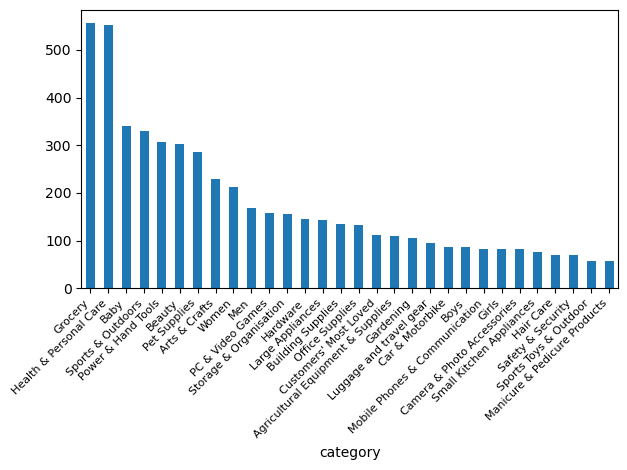

In [26]:
best_seller_proportion.plot(kind="bar")

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [8]:
def remove_price_outliers(df):
    Q1 = df["price"].quantile(0.25)
    Q3 = df["price"].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep only rows that are not outliers
    df_clean = df[
        (df["price"] >= lower_bound) &
        (df["price"] <= upper_bound)
    ].copy()

    return df_clean
df_clean =remove_price_outliers(df)

In [9]:
# Find the top 20 categories
top_20_categories = df_clean["category"].value_counts().head(20).index

# Filter the dataframe
df_top_20 = df_clean[df_clean["category"].isin(top_20_categories)]




In [10]:
crosstab_result2 = pd.crosstab(df_top_20['category'], df_top_20['price'])

C:\Users\matt9\AppData\Local\Temp\ipykernel_8744\3191257019.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_20, x='category', y='price', palette="coolwarm")


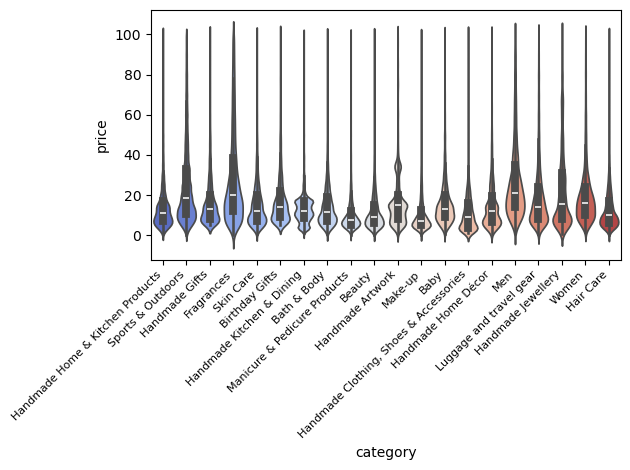

In [27]:
sns.violinplot(data=df_top_20, x='category', y='price', palette="coolwarm")
plt.xticks(
    rotation=45,
    ha="right",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [12]:
# Find the top 10 categories
top_10_categories = df_clean["category"].value_counts().head(10).index

# Filter the dataframe
df_top_10 = df_clean[df_clean["category"].isin(top_10_categories)]


C:\Users\matt9\AppData\Local\Temp\ipykernel_8744\701880871.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_10, x='category', y='price', palette="coolwarm")


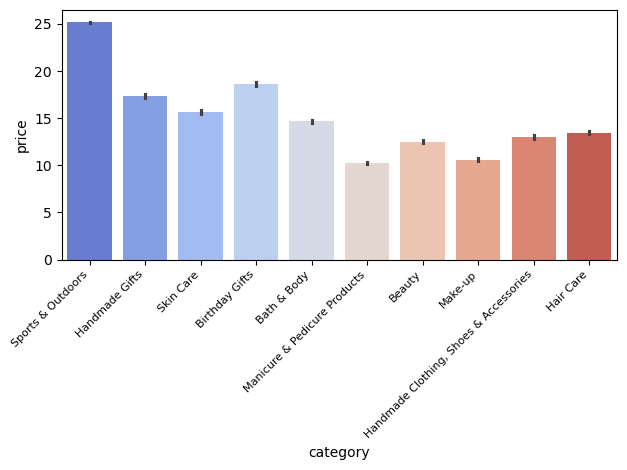

In [28]:
sns.barplot(data=df_top_10, x='category', y='price', palette="coolwarm")
plt.xticks(
    rotation=45,
    ha="right",
    fontsize=8
)

plt.tight_layout()
plt.show()

C:\Users\matt9\AppData\Local\Temp\ipykernel_8744\1510245855.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10, x='category', y='stars', palette="coolwarm")


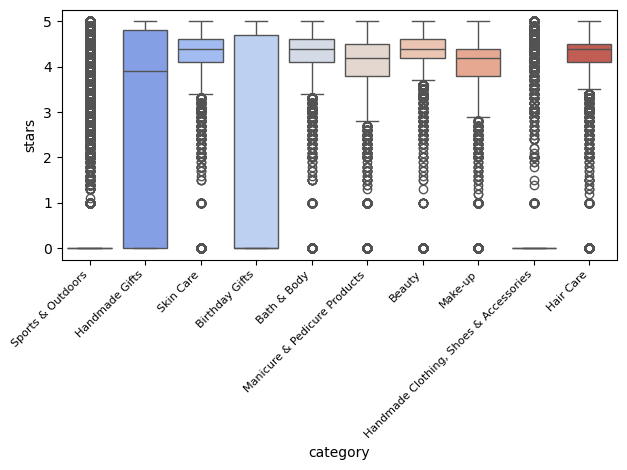

In [29]:
sns.boxplot(data=df_top_10, x='category', y='stars', palette="coolwarm")

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [31]:
median_stars = df_top_10.groupby("category")["stars"].median()
median_stars.sort_values(ascending=False).head(10)

category
Bath & Body                               4.4
Beauty                                    4.4
Hair Care                                 4.4
Skin Care                                 4.4
Make-up                                   4.2
Manicure & Pedicure Products              4.2
Handmade Gifts                            3.9
Birthday Gifts                            0.0
Handmade Clothing, Shoes & Accessories    0.0
Sports & Outdoors                         0.0
Name: stars, dtype: float64

In [15]:
crosstab_result = pd.crosstab(df_clean['stars'], df_clean['price'])

In [16]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(662382.0835902255), np.float64(0.0))

In [17]:
association(crosstab_result, method="cramer")

0.087379252563221

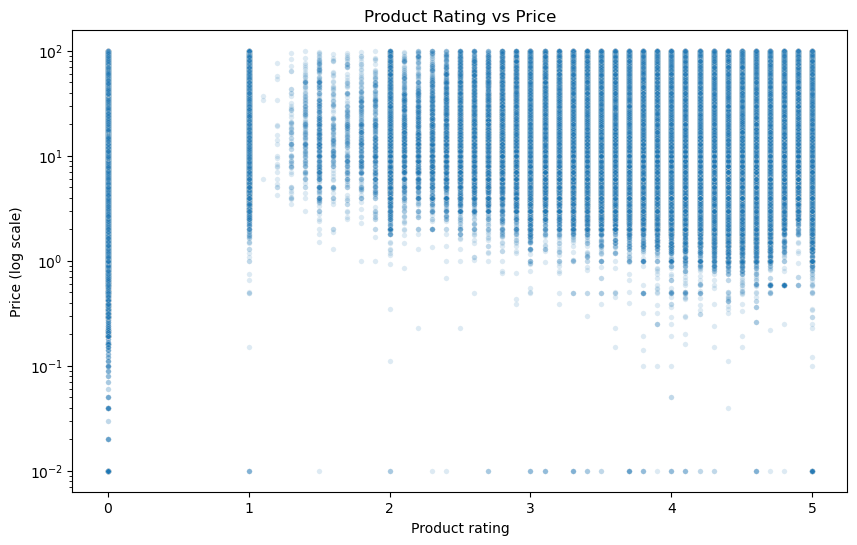

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="stars",
    y="price",
    alpha=0.15,  # more transparent
    s=15         # smaller points
)

plt.yscale("log")
plt.title("Product Rating vs Price")
plt.xlabel("Product rating")
plt.ylabel("Price (log scale)")
plt.show()

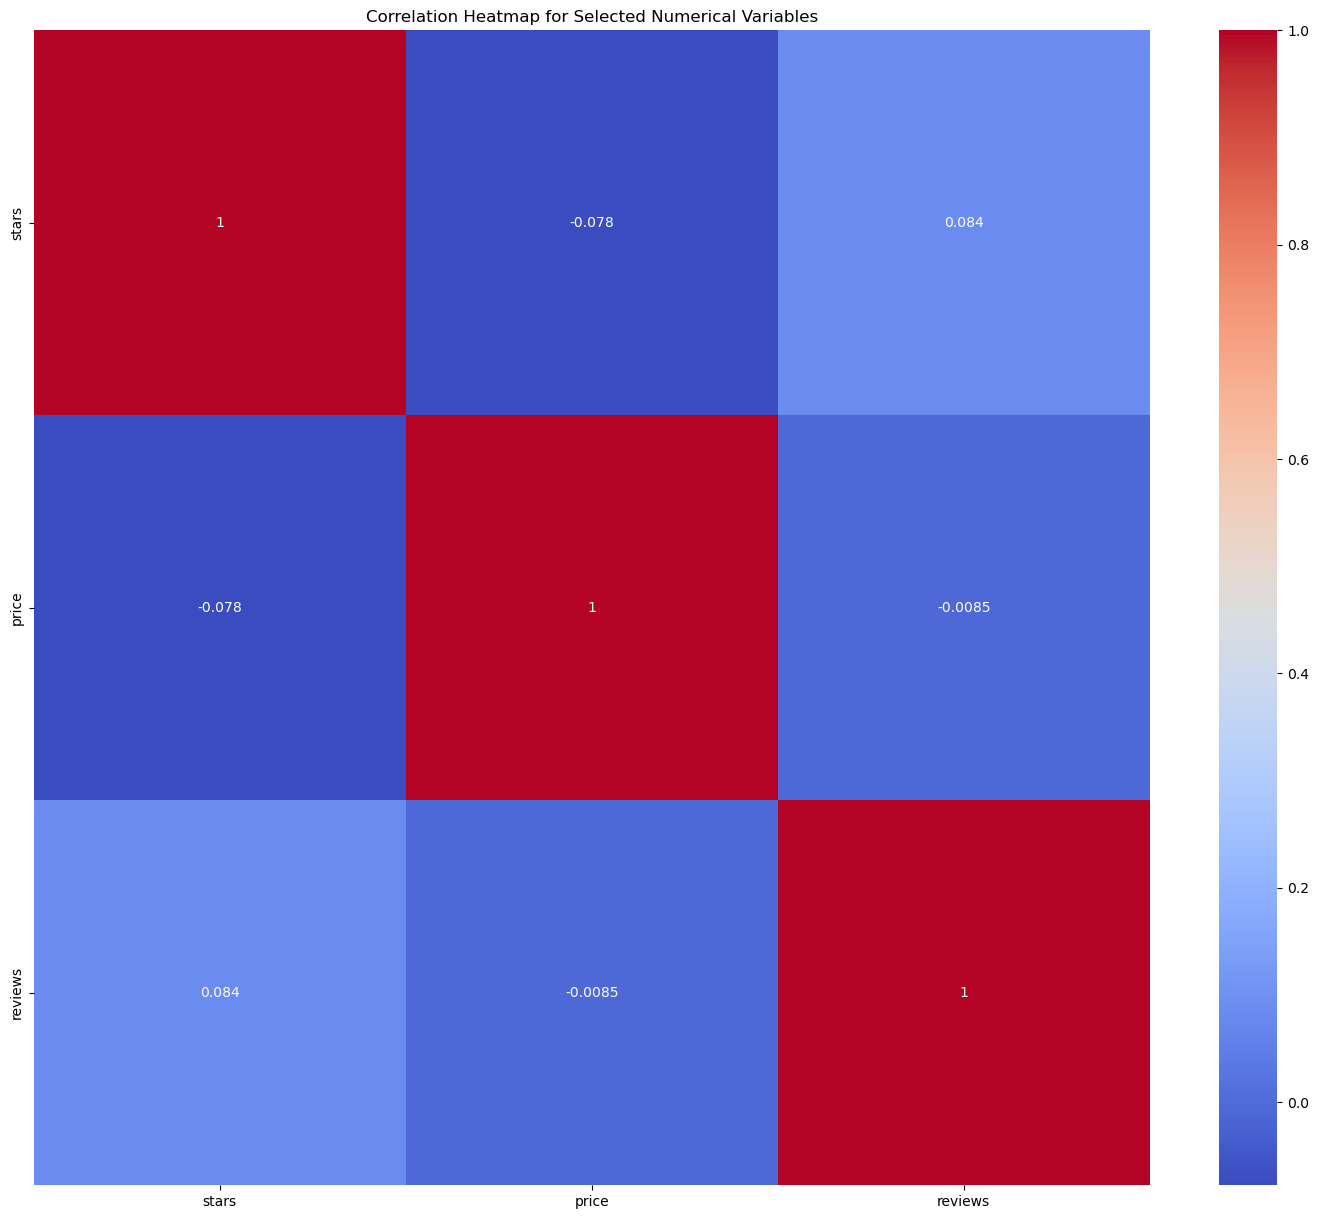

In [19]:
correlation_matrix = df_clean[['stars', 'price','reviews']].corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

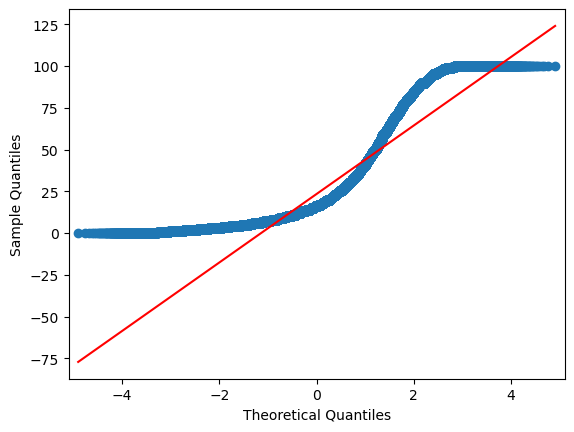

In [20]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(df_clean['price'], line='s');